In [2]:
import pandas as pd

df = pd.read_excel("/content/Sales Data.xlsx")

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Columns:", df.columns.tolist())

Dataset loaded successfully.
Rows: 185950
Columns: 11
Columns: ['Unnamed: 0', 'Order ID', 'Product', 'Quantity Ordered', 'Price Each', 'Order Date', 'Purchase Address', 'Month', 'Sales', 'City', 'Hour']


In [3]:
print("DATA TYPES")
print("=" * 50)
print(df.dtypes)

print("\nMISSING VALUES")
print("=" * 50)
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print("=" * 50)
print(df.duplicated().sum())

DATA TYPES
Unnamed: 0                   int64
Order ID                     int64
Product                     object
Quantity Ordered             int64
Price Each                 float64
Order Date          datetime64[ns]
Purchase Address            object
Month                        int64
Sales                      float64
City                        object
Hour                         int64
dtype: object

MISSING VALUES
Unnamed: 0          0
Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
Month               0
Sales               0
City                0
Hour                0
dtype: int64

DUPLICATE ROWS
0


In [4]:
print(df[[
    "Quantity Ordered",
    "Price Each",
    "Sales",
    "Month",
    "Hour"
]].describe())

       Quantity Ordered     Price Each          Sales          Month  \
count     185950.000000  185950.000000  185950.000000  185950.000000   
mean           1.124383     184.399735     185.490917       7.059140   
std            0.442793     332.731330     332.919771       3.502996   
min            1.000000       2.990000       2.990000       1.000000   
25%            1.000000      11.950000      11.950000       4.000000   
50%            1.000000      14.950000      14.950000       7.000000   
75%            1.000000     150.000000     150.000000      10.000000   
max            9.000000    1700.000000    3400.000000      12.000000   

                Hour  
count  185950.000000  
mean       14.413305  
std         5.423416  
min         0.000000  
25%        11.000000  
50%        15.000000  
75%        19.000000  
max        23.000000  


In [5]:
total_revenue = df["Sales"].sum()

total_orders = df["Order ID"].nunique()

average_order_value = total_revenue / total_orders

total_quantity = df["Quantity Ordered"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Total Unique Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))
print("Total Quantity Sold:", total_quantity)

Total Revenue: 34492035.97
Total Unique Orders: 178437
Average Order Value: 193.3
Total Quantity Sold: 209079


In [6]:
top_products = (
    df.groupby("Product")["Quantity Ordered"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

top_products.columns = ["Product", "Total_Quantity_Sold"]

print(top_products.head(10).to_string(index=False))

                   Product  Total_Quantity_Sold
    AAA Batteries (4-pack)                31017
     AA Batteries (4-pack)                27635
      USB-C Charging Cable                23975
  Lightning Charging Cable                23217
          Wired Headphones                20557
  Apple Airpods Headphones                15661
Bose SoundSport Headphones                13457
          27in FHD Monitor                 7550
                    iPhone                 6849
    27in 4K Gaming Monitor                 6244


In [7]:
product_revenue = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_revenue.columns = ["Product", "Total_Revenue"]

print(product_revenue.head(10).to_string(index=False))

                   Product  Total_Revenue
        Macbook Pro Laptop     8037600.00
                    iPhone     4794300.00
           ThinkPad Laptop     4129958.70
              Google Phone     3319200.00
    27in 4K Gaming Monitor     2435097.56
    34in Ultrawide Monitor     2355558.01
  Apple Airpods Headphones     2349150.00
             Flatscreen TV     1445700.00
Bose SoundSport Headphones     1345565.43
          27in FHD Monitor     1132424.50


In [8]:
monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Month")
)

print(monthly_sales.to_string(index=False))

 Month      Sales
     1 1822256.73
     2 2202022.42
     3 2807100.38
     4 3390670.24
     5 3152606.75
     6 2577802.26
     7 2647775.76
     8 2244467.88
     9 2097560.13
    10 3736726.88
    11 3199603.20
    12 4613443.34


In [9]:
city_sales = (
    df.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

city_sales.columns = ["City", "Total_Revenue"]

print(city_sales.to_string(index=False))

          City  Total_Revenue
 San Francisco     8262203.91
   Los Angeles     5452570.80
 New York City     4664317.43
        Boston     3661642.01
       Atlanta     2795498.58
        Dallas     2767975.40
       Seattle     2747755.48
      Portland     2320490.61
        Austin     1819581.75


In [10]:
hourly_sales = (
    df.groupby("Hour")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Hour")
)

print(hourly_sales.to_string(index=False))

 Hour      Sales
    0  713721.27
    1  460866.88
    2  234851.44
    3  145757.89
    4  162661.01
    5  230679.82
    6  448113.00
    7  744854.12
    8 1192348.97
    9 1639030.58
   10 1944286.77
   11 2300610.24
   12 2316821.34
   13 2155389.80
   14 2083672.73
   15 1941549.60
   16 1904601.31
   17 2129361.61
   18 2219348.30
   19 2412938.54
   20 2281716.24
   21 2042000.86
   22 1607549.21
   23 1179304.44


In [11]:
city_quantity = (
    df.groupby("City")["Quantity Ordered"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

city_quantity.columns = ["City", "Total_Quantity_Sold"]

print(city_quantity.to_string(index=False))

          City  Total_Quantity_Sold
 San Francisco                50239
   Los Angeles                33289
 New York City                27932
        Boston                22528
        Dallas                16730
       Atlanta                16602
       Seattle                16553
      Portland                14053
        Austin                11153


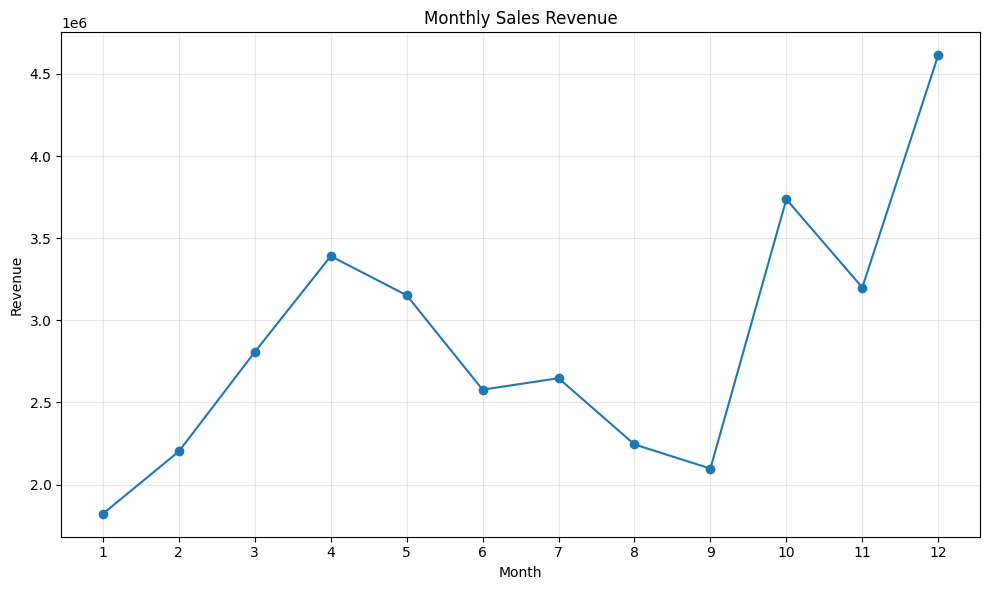

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1, 13))

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "monthly_sales_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

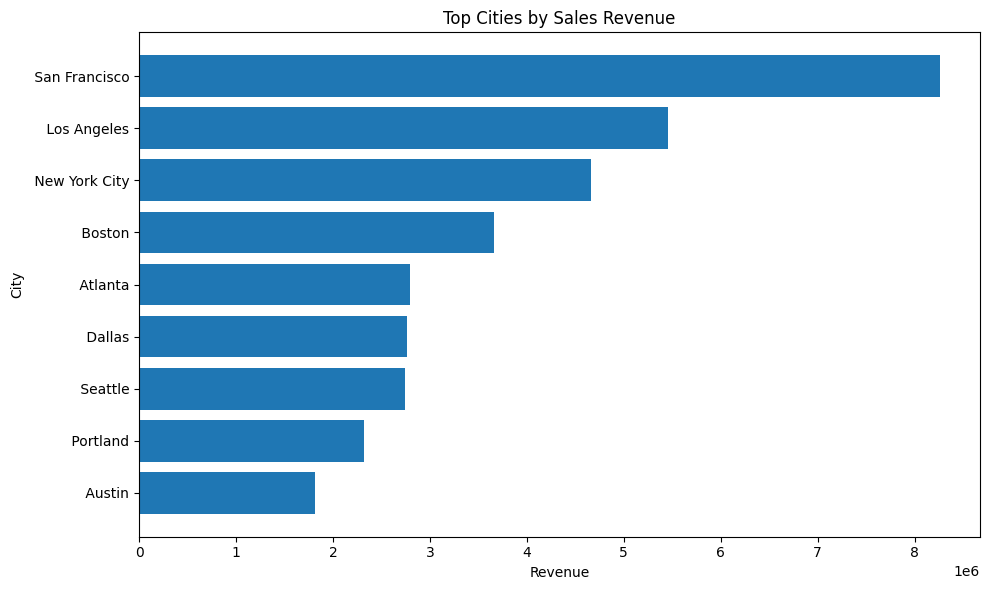

In [13]:
top_cities = city_sales.head(10).sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_cities["City"],
    top_cities["Total_Revenue"]
)

plt.title("Top Cities by Sales Revenue")
plt.xlabel("Revenue")
plt.ylabel("City")

plt.tight_layout()

plt.savefig(
    "top_cities_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

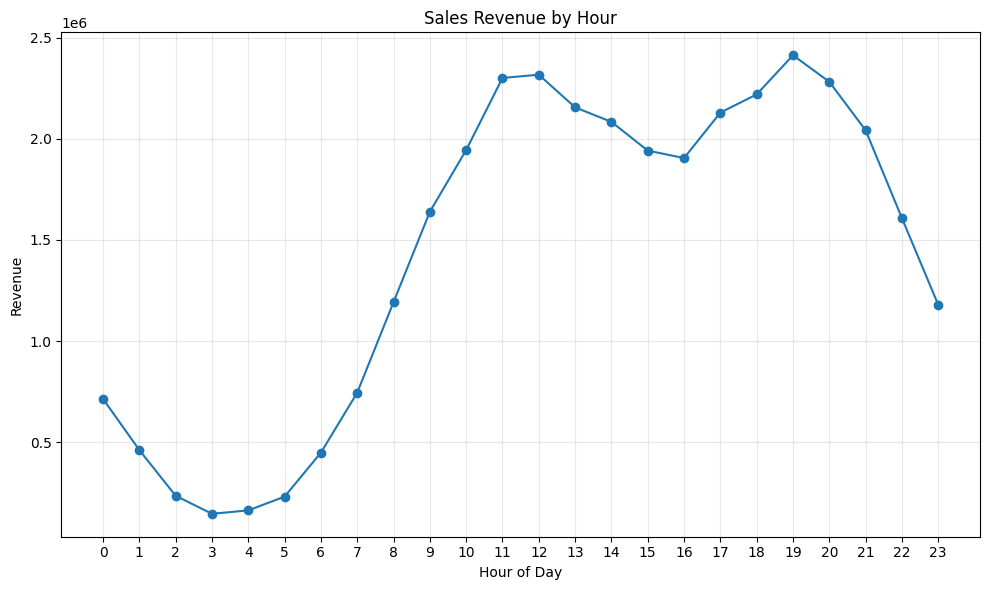

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    hourly_sales["Hour"],
    hourly_sales["Sales"],
    marker="o"
)

plt.title("Sales Revenue by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(0, 24))

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "hourly_sales_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

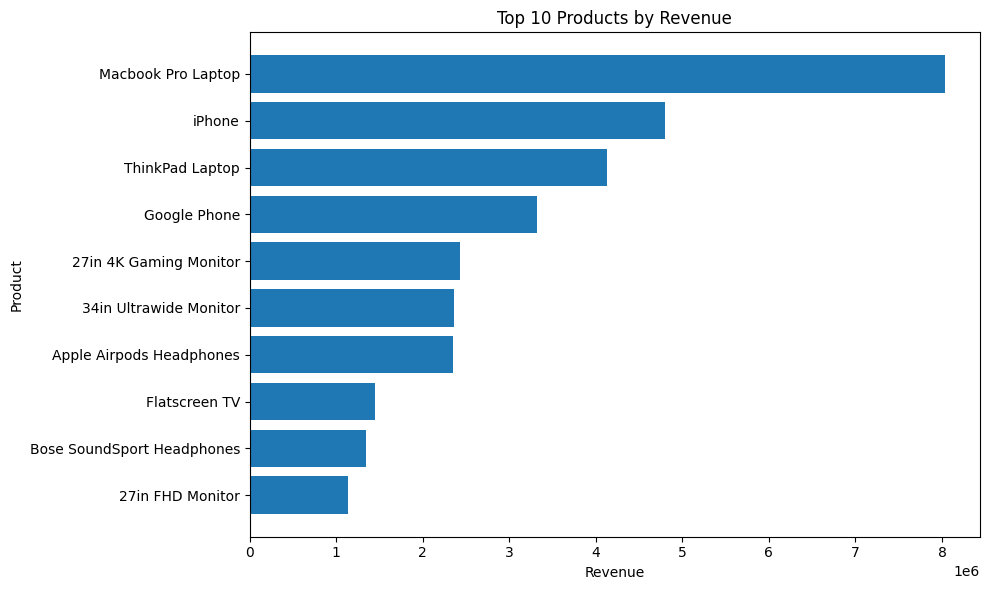

In [15]:
top_10_revenue_products = product_revenue.head(10).sort_values("Total_Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_revenue_products["Product"],
    top_10_revenue_products["Total_Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "top_10_products_by_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

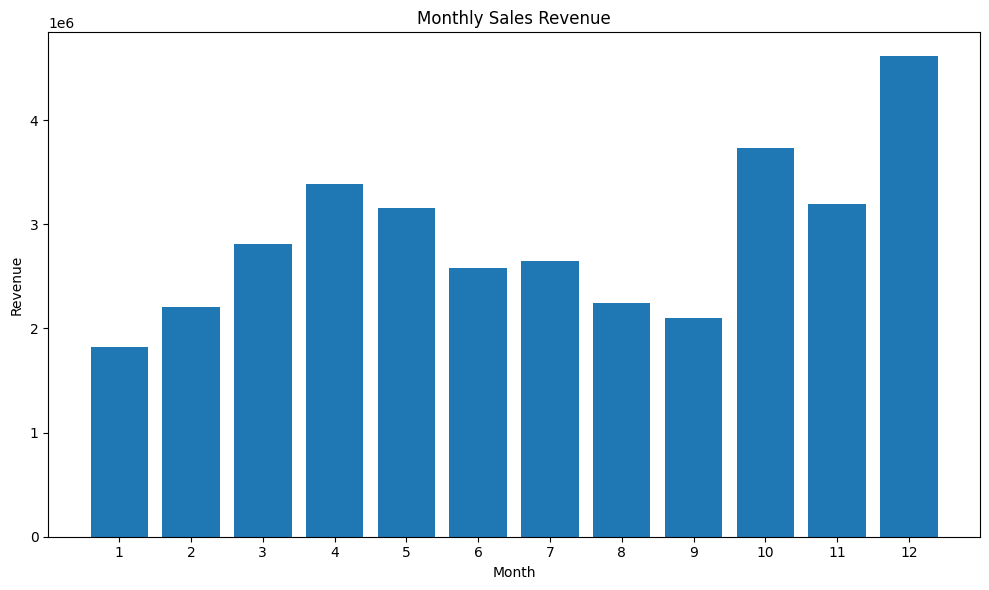

In [16]:
plt.figure(figsize=(10, 6))

plt.bar(
    monthly_sales["Month"],
    monthly_sales["Sales"]
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1, 13))

plt.tight_layout()

plt.savefig(
    "monthly_sales_revenue_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
monthly_growth = monthly_sales.copy()

monthly_growth["Growth_%"] = (
    monthly_growth["Sales"]
    .pct_change()
    .mul(100)
)

print(monthly_growth.to_string(index=False))

 Month      Sales   Growth_%
     1 1822256.73        NaN
     2 2202022.42  20.840405
     3 2807100.38  27.478283
     4 3390670.24  20.789063
     5 3152606.75  -7.021134
     6 2577802.26 -18.232673
     7 2647775.76   2.714463
     8 2244467.88 -15.231950
     9 2097560.13  -6.545326
    10 3736726.88  78.146353
    11 3199603.20 -14.374176
    12 4613443.34  44.187984


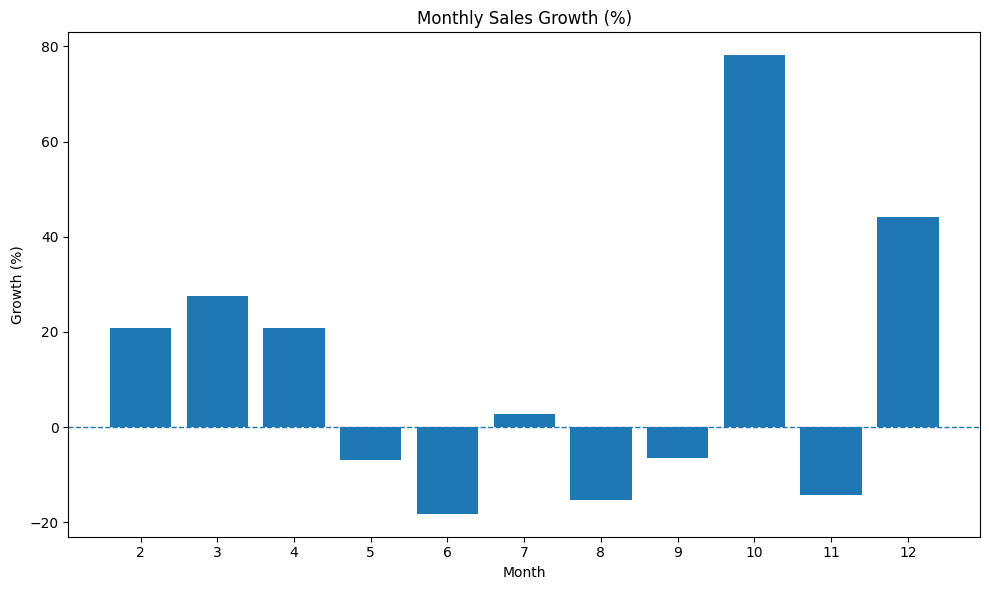

In [18]:
growth_plot = monthly_growth.dropna(subset=["Growth_%"])

plt.figure(figsize=(10, 6))

plt.bar(
    growth_plot["Month"],
    growth_plot["Growth_%"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Monthly Sales Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(range(2, 13))

plt.tight_layout()

plt.savefig(
    "monthly_sales_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
top_10_cities = city_sales.head(10).copy()

print(top_10_cities.to_string(index=False))

          City  Total_Revenue
 San Francisco     8262203.91
   Los Angeles     5452570.80
 New York City     4664317.43
        Boston     3661642.01
       Atlanta     2795498.58
        Dallas     2767975.40
       Seattle     2747755.48
      Portland     2320490.61
        Austin     1819581.75


In [20]:
top_10_revenue_products = product_revenue.head(10).copy()

print(top_10_revenue_products.to_string(index=False))

                   Product  Total_Revenue
        Macbook Pro Laptop     8037600.00
                    iPhone     4794300.00
           ThinkPad Laptop     4129958.70
              Google Phone     3319200.00
    27in 4K Gaming Monitor     2435097.56
    34in Ultrawide Monitor     2355558.01
  Apple Airpods Headphones     2349150.00
             Flatscreen TV     1445700.00
Bose SoundSport Headphones     1345565.43
          27in FHD Monitor     1132424.50


In [21]:
avg_product_price = (
    df.groupby("Product")["Price Each"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

avg_product_price.columns = ["Product", "Average_Price"]

print(avg_product_price.head(10).to_string(index=False))

               Product  Average_Price
    Macbook Pro Laptop        1700.00
       ThinkPad Laptop         999.99
                iPhone         700.00
    LG Washing Machine         600.00
              LG Dryer         600.00
          Google Phone         600.00
       Vareebadd Phone         400.00
27in 4K Gaming Monitor         389.99
34in Ultrawide Monitor         379.99
         Flatscreen TV         300.00


In [22]:
city_orders = (
    df.groupby("City")["Order ID"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

city_orders.columns = ["City", "Unique_Orders"]

print(city_orders.to_string(index=False))

          City  Unique_Orders
 San Francisco          42898
   Los Angeles          28498
 New York City          23848
        Boston          19092
       Atlanta          14253
        Dallas          14240
       Seattle          14119
      Portland          11980
        Austin           9509


In [23]:
city_aov = (
    df.groupby("City")
    .agg(
        Total_Revenue=("Sales", "sum"),
        Unique_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

city_aov["Average_Order_Value"] = (
    city_aov["Total_Revenue"] / city_aov["Unique_Orders"]
)

city_aov = city_aov.sort_values(
    "Average_Order_Value",
    ascending=False
)

print(city_aov.to_string(index=False))

          City  Total_Revenue  Unique_Orders  Average_Order_Value
       Atlanta     2795498.58          14253           196.134048
 New York City     4664317.43          23848           195.585266
       Seattle     2747755.48          14119           194.614029
        Dallas     2767975.40          14240           194.380295
      Portland     2320490.61          11980           193.697046
 San Francisco     8262203.91          42898           192.601145
        Boston     3661642.01          19092           191.789336
        Austin     1819581.75           9509           191.353639
   Los Angeles     5452570.80          28498           191.331700


In [24]:
monthly_orders = (
    df.groupby("Month")["Order ID"]
    .nunique()
    .reset_index()
)

monthly_orders.columns = ["Month", "Unique_Orders"]

print(monthly_orders.to_string(index=False))

 Month  Unique_Orders
     1           9293
     2          11496
     3          14549
     4          17528
     5          15836
     6          12989
     7          13761
     8          11484
     9          11202
    10          19436
    11          16859
    12          24004


In [25]:
monthly_analysis = (
    monthly_sales
    .merge(monthly_orders, on="Month")
)

monthly_quantity = (
    df.groupby("Month")["Quantity Ordered"]
    .sum()
    .reset_index()
)

monthly_quantity.columns = ["Month", "Quantity_Sold"]

monthly_analysis = monthly_analysis.merge(
    monthly_quantity,
    on="Month"
)

monthly_analysis["Average_Order_Value"] = (
    monthly_analysis["Sales"] /
    monthly_analysis["Unique_Orders"]
)

print(monthly_analysis.to_string(index=False))

 Month      Sales  Unique_Orders  Quantity_Sold  Average_Order_Value
     1 1822256.73           9293          10903           196.089178
     2 2202022.42          11496          13449           191.546835
     3 2807100.38          14549          17005           192.941122
     4 3390670.24          17528          20558           193.443076
     5 3152606.75          15836          18667           199.078476
     6 2577802.26          12989          15253           198.460410
     7 2647775.76          13761          16072           192.411581
     8 2244467.88          11484          13448           195.443041
     9 2097560.13          11202          13109           187.248717
    10 3736726.88          19436          22703           192.258020
    11 3199603.20          16859          19798           189.786061
    12 4613443.34          24004          28114           192.194773


In [26]:
top_hours = (
    hourly_sales
    .sort_values("Sales", ascending=False)
    .head(5)
)

print(top_hours.to_string(index=False))

 Hour      Sales
   19 2412938.54
   12 2316821.34
   11 2300610.24
   20 2281716.24
   18 2219348.30


In [27]:
top_5_products = top_products.head(5)

print(top_5_products.to_string(index=False))

                 Product  Total_Quantity_Sold
  AAA Batteries (4-pack)                31017
   AA Batteries (4-pack)                27635
    USB-C Charging Cable                23975
Lightning Charging Cable                23217
        Wired Headphones                20557


In [28]:
top_5_revenue_products = product_revenue.head(5)

print(top_5_revenue_products.to_string(index=False))

               Product  Total_Revenue
    Macbook Pro Laptop     8037600.00
                iPhone     4794300.00
       ThinkPad Laptop     4129958.70
          Google Phone     3319200.00
27in 4K Gaming Monitor     2435097.56


In [29]:
product_performance = (
    df.groupby("Product")
    .agg(
        Quantity_Sold=("Quantity Ordered", "sum"),
        Total_Revenue=("Sales", "sum"),
        Average_Price=("Price Each", "mean")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

print(product_performance.to_string(index=False))

                   Product  Quantity_Sold  Total_Revenue  Average_Price
        Macbook Pro Laptop           4728     8037600.00        1700.00
                    iPhone           6849     4794300.00         700.00
           ThinkPad Laptop           4130     4129958.70         999.99
              Google Phone           5532     3319200.00         600.00
    27in 4K Gaming Monitor           6244     2435097.56         389.99
    34in Ultrawide Monitor           6199     2355558.01         379.99
  Apple Airpods Headphones          15661     2349150.00         150.00
             Flatscreen TV           4819     1445700.00         300.00
Bose SoundSport Headphones          13457     1345565.43          99.99
          27in FHD Monitor           7550     1132424.50         149.99
           Vareebadd Phone           2068      827200.00         400.00
              20in Monitor           4129      454148.71         109.99
        LG Washing Machine            666      399600.00        

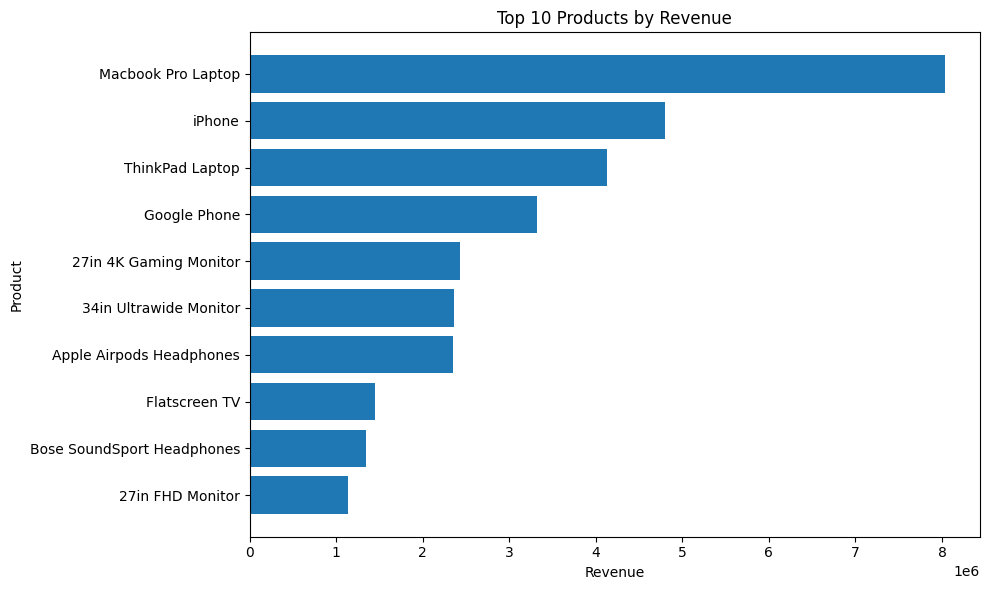

In [30]:
top_10_product_chart = product_performance.head(10).sort_values(
    "Total_Revenue"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_product_chart["Product"],
    top_10_product_chart["Total_Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "top_10_product_revenue_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

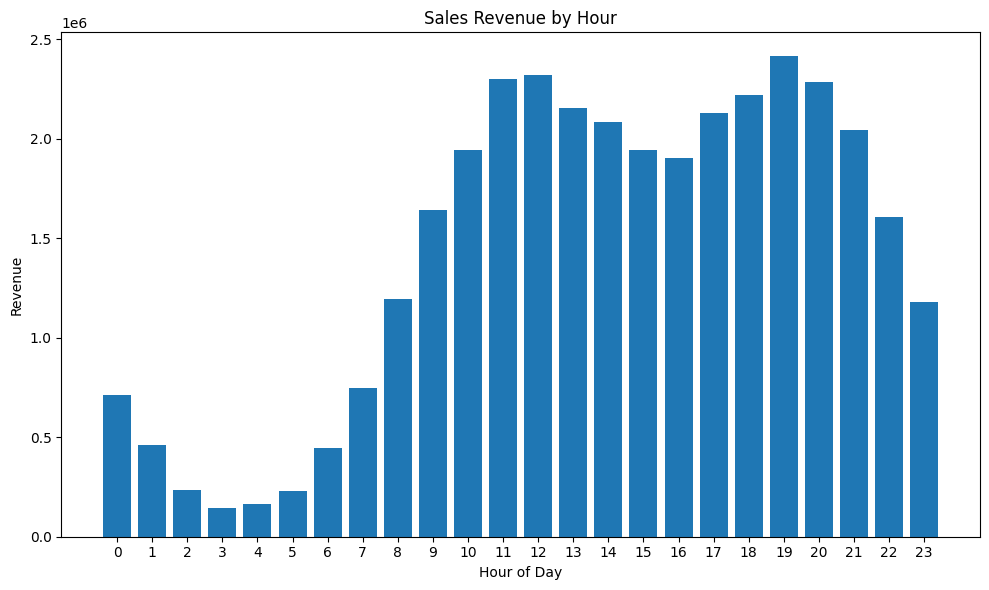

In [31]:
plt.figure(figsize=(10, 6))

plt.bar(
    hourly_sales["Hour"],
    hourly_sales["Sales"]
)

plt.title("Sales Revenue by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(24))

plt.tight_layout()

plt.savefig(
    "hourly_sales_revenue_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
product_contribution = product_performance.copy()

product_contribution["Revenue_Contribution_%"] = (
    product_contribution["Total_Revenue"]
    / product_contribution["Total_Revenue"].sum()
    * 100
)

product_contribution = product_contribution.sort_values(
    "Revenue_Contribution_%",
    ascending=False
)

print(
    product_contribution[
        ["Product", "Total_Revenue", "Revenue_Contribution_%"]
    ].head(10).to_string(index=False)
)

                   Product  Total_Revenue  Revenue_Contribution_%
        Macbook Pro Laptop     8037600.00               23.302771
                    iPhone     4794300.00               13.899730
           ThinkPad Laptop     4129958.70               11.973659
              Google Phone     3319200.00                9.623091
    27in 4K Gaming Monitor     2435097.56                7.059884
    34in Ultrawide Monitor     2355558.01                6.829281
  Apple Airpods Headphones     2349150.00                6.810703
             Flatscreen TV     1445700.00                4.191402
Bose SoundSport Headphones     1345565.43                3.901090
          27in FHD Monitor     1132424.50                3.283148


In [34]:
top_5_revenue_share = (
    product_performance
    .head(5)["Total_Revenue"]
    .sum()
    / total_revenue
    * 100
)

print(
    "Top 5 Products Revenue:",
    round(product_performance.head(5)["Total_Revenue"].sum(), 2)
)

print(
    "Top 5 Revenue Contribution:",
    round(top_5_revenue_share, 2),
    "%"
)

Top 5 Products Revenue: 22716156.26
Top 5 Revenue Contribution: 65.86 %


In [35]:
city_contribution = city_sales.copy()

city_contribution["Revenue_Contribution_%"] = (
    city_contribution["Total_Revenue"]
    / city_contribution["Total_Revenue"].sum()
    * 100
)

city_contribution = city_contribution.sort_values(
    "Revenue_Contribution_%",
    ascending=False
)

print(
    city_contribution[
        ["City", "Total_Revenue", "Revenue_Contribution_%"]
    ].to_string(index=False)
)

          City  Total_Revenue  Revenue_Contribution_%
 San Francisco     8262203.91               23.953947
   Los Angeles     5452570.80               15.808202
 New York City     4664317.43               13.522882
        Boston     3661642.01               10.615906
       Atlanta     2795498.58                8.104765
        Dallas     2767975.40                8.024970
       Seattle     2747755.48                7.966348
      Portland     2320490.61                6.727613
        Austin     1819581.75                5.275368


In [36]:
top_5_city_contribution = city_contribution.head(5)

print(
    top_5_city_contribution[
        ["City", "Total_Revenue", "Revenue_Contribution_%"]
    ].to_string(index=False)
)

          City  Total_Revenue  Revenue_Contribution_%
 San Francisco     8262203.91               23.953947
   Los Angeles     5452570.80               15.808202
 New York City     4664317.43               13.522882
        Boston     3661642.01               10.615906
       Atlanta     2795498.58                8.104765


In [37]:
top_5_city_share = (
    city_contribution.head(5)["Total_Revenue"].sum()
    / total_revenue
    * 100
)

print(
    "Top 5 Cities Revenue:",
    round(city_contribution.head(5)["Total_Revenue"].sum(), 2)
)

print(
    "Top 5 Cities Revenue Contribution:",
    round(top_5_city_share, 2),
    "%"
)

Top 5 Cities Revenue: 24836232.73
Top 5 Cities Revenue Contribution: 72.01 %


In [38]:
print("TOP 5 PRODUCT REVENUE CONTRIBUTION")
print("=" * 45)
print(f"{top_5_revenue_share:.2f}%")

print("\nTOP 5 CITY REVENUE CONTRIBUTION")
print("=" * 45)
print(f"{top_5_city_share:.2f}%")

TOP 5 PRODUCT REVENUE CONTRIBUTION
65.86%

TOP 5 CITY REVENUE CONTRIBUTION
72.01%


In [39]:
print("SALES ANALYSIS KEY PERFORMANCE INDICATORS")
print("=" * 55)

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

print(
    f"Top Product by Revenue: "
    f"{product_performance.iloc[0]['Product']} "
    f"(${product_performance.iloc[0]['Total_Revenue']:,.2f})"
)

print(
    f"Top City by Revenue: "
    f"{city_contribution.iloc[0]['City']} "
    f"(${city_contribution.iloc[0]['Total_Revenue']:,.2f})"
)

print(
    f"Top Sales Hour: "
    f"{int(top_hours.iloc[0]['Hour'])}:00 "
    f"(${top_hours.iloc[0]['Sales']:,.2f})"
)

print(f"Top 5 Product Revenue Contribution: {top_5_revenue_share:.2f}%")
print(f"Top 5 City Revenue Contribution: {top_5_city_share:.2f}%")

SALES ANALYSIS KEY PERFORMANCE INDICATORS
Total Revenue: $34,492,035.97
Total Unique Orders: 178,437
Total Quantity Sold: 209,079
Average Order Value: $193.30
Top Product by Revenue: Macbook Pro Laptop ($8,037,600.00)
Top City by Revenue:  San Francisco ($8,262,203.91)
Top Sales Hour: 19:00 ($2,412,938.54)
Top 5 Product Revenue Contribution: 65.86%
Top 5 City Revenue Contribution: 72.01%


In [40]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Unique Orders",
        "Total Quantity Sold",
        "Average Order Value",
        "Top Product by Revenue",
        "Top City by Revenue",
        "Top Sales Hour",
        "Top 5 Product Revenue Contribution",
        "Top 5 City Revenue Contribution"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_quantity,
        average_order_value,
        product_performance.iloc[0]["Product"],
        city_contribution.iloc[0]["City"],
        f"{int(top_hours.iloc[0]['Hour'])}:00",
        top_5_revenue_share,
        top_5_city_share
    ]
})

print(kpi_summary.to_string(index=False))

                            Metric              Value
                     Total Revenue        34492035.97
               Total Unique Orders             178437
               Total Quantity Sold             209079
               Average Order Value         193.300918
            Top Product by Revenue Macbook Pro Laptop
               Top City by Revenue      San Francisco
                    Top Sales Hour              19:00
Top 5 Product Revenue Contribution          65.859134
   Top 5 City Revenue Contribution          72.005702


In [41]:
kpi_summary.to_csv(
    "sales_analysis_kpi_summary.csv",
    index=False
)

print("KPI summary saved successfully.")

KPI summary saved successfully.


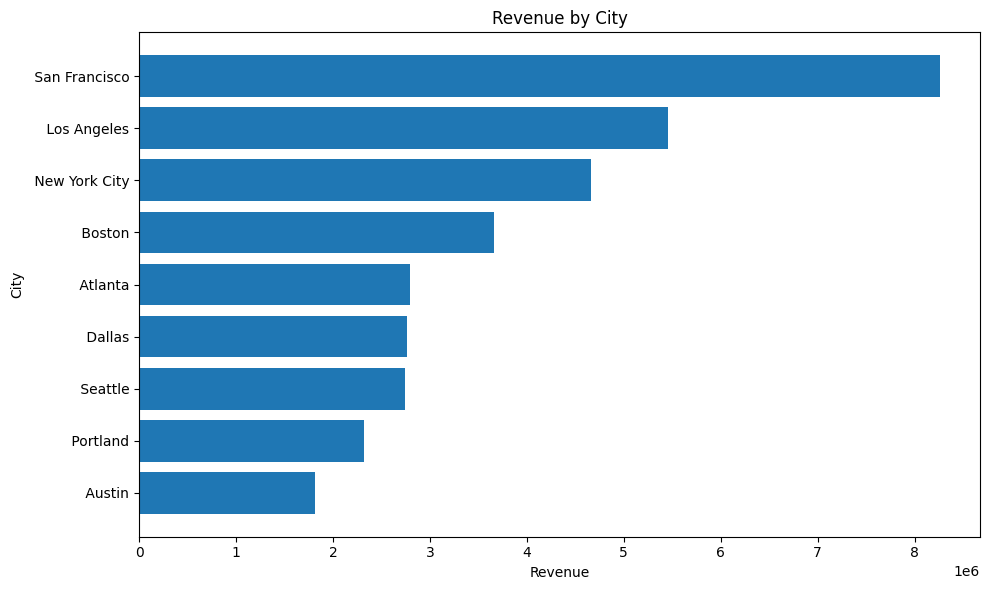

In [42]:
plt.figure(figsize=(10, 6))

city_chart = city_contribution.sort_values("Total_Revenue")

plt.barh(
    city_chart["City"],
    city_chart["Total_Revenue"]
)

plt.title("Revenue by City")
plt.xlabel("Revenue")
plt.ylabel("City")

plt.tight_layout()

plt.savefig(
    "revenue_by_city.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

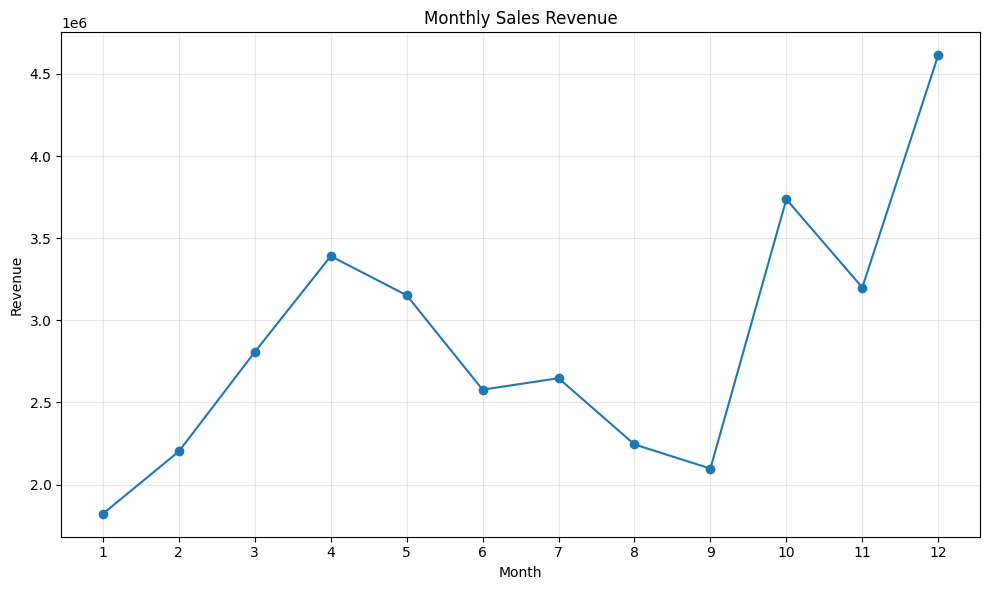

In [43]:
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Sales"],
    marker="o"
)

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(range(1, 13))

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

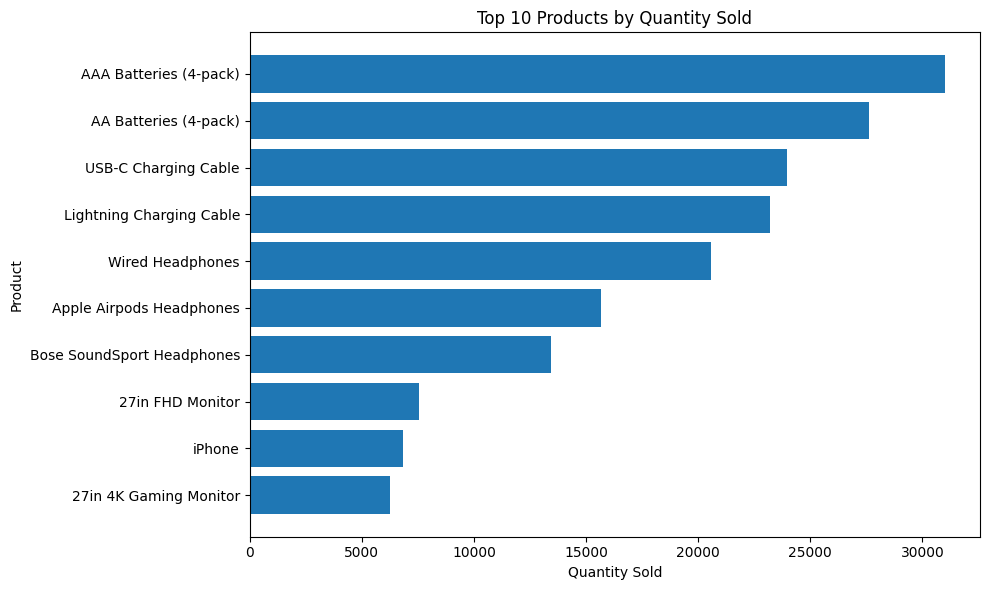

In [44]:
top_10_quantity = (
    product_performance
    .sort_values("Quantity_Sold", ascending=False)
    .head(10)
    .sort_values("Quantity_Sold")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_quantity["Product"],
    top_10_quantity["Quantity_Sold"]
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    "top_10_products_by_quantity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

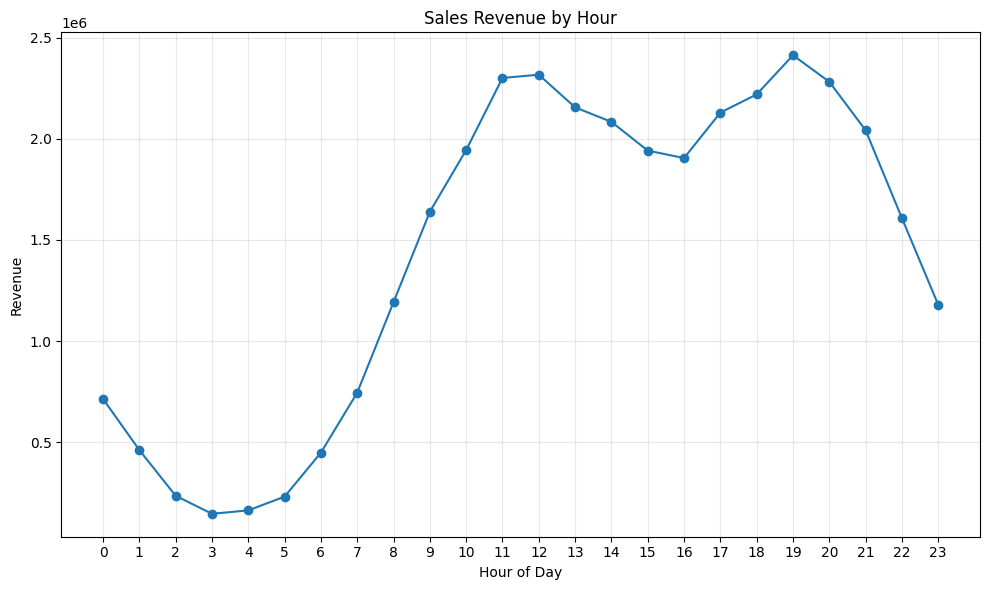

In [45]:
plt.figure(figsize=(10, 6))

plt.plot(
    hourly_sales["Hour"],
    hourly_sales["Sales"],
    marker="o"
)

plt.title("Sales Revenue by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(24))

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "hourly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

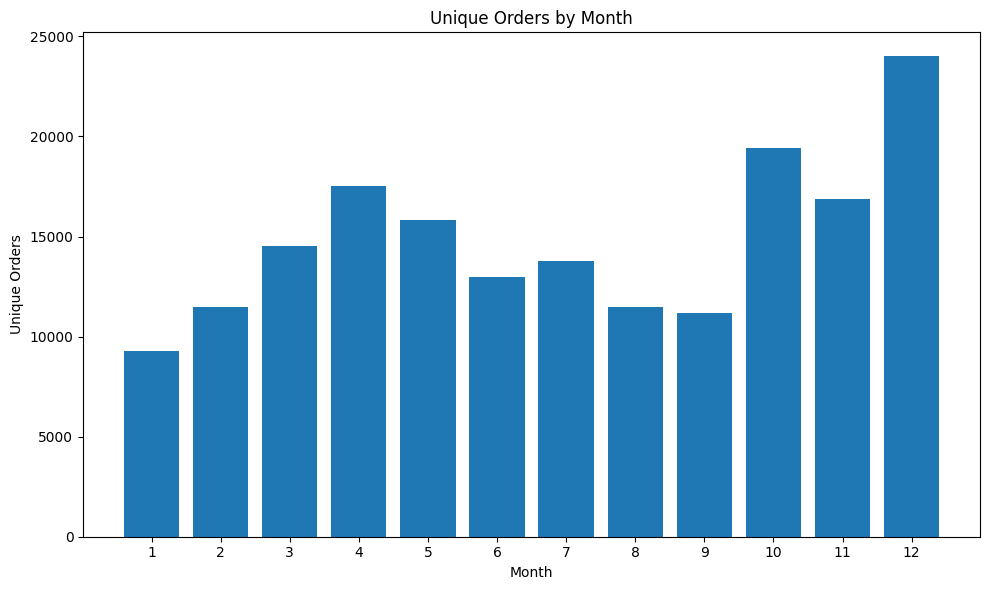

In [46]:
plt.figure(figsize=(10, 6))

plt.bar(
    monthly_orders["Month"],
    monthly_orders["Unique_Orders"]
)

plt.title("Unique Orders by Month")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.xticks(range(1, 13))

plt.tight_layout()

plt.savefig(
    "monthly_unique_orders.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
monthly_analysis.to_csv(
    "monthly_sales_analysis.csv",
    index=False
)

print("Monthly sales analysis saved successfully.")

Monthly sales analysis saved successfully.


In [48]:
product_performance.to_csv(
    "product_performance_analysis.csv",
    index=False
)

print("Product performance analysis saved successfully.")

Product performance analysis saved successfully.


In [49]:
city_contribution.to_csv(
    "city_revenue_analysis.csv",
    index=False
)

print("City revenue analysis saved successfully.")

City revenue analysis saved successfully.


In [50]:
hourly_sales.to_csv(
    "hourly_sales_analysis.csv",
    index=False
)

print("Hourly sales analysis saved successfully.")

Hourly sales analysis saved successfully.


In [51]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Unique Orders",
        "Total Quantity Sold",
        "Average Order Value",
        "Top Product by Revenue",
        "Top City by Revenue",
        "Top Sales Hour",
        "Top 5 Product Revenue Contribution",
        "Top 5 City Revenue Contribution",
        "Highest Revenue Month",
        "Highest Revenue Month Sales",
        "Highest Growth Month",
        "Highest Growth Percentage"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_quantity,
        average_order_value,
        product_performance.iloc[0]["Product"],
        city_contribution.iloc[0]["City"],
        f"{int(top_hours.iloc[0]['Hour'])}:00",
        top_5_revenue_share,
        top_5_city_share,
        monthly_analysis.loc[
            monthly_analysis["Sales"].idxmax(), "Month"
        ],
        monthly_analysis["Sales"].max(),
        monthly_growth.loc[
            monthly_growth["Growth_%"].idxmax(), "Month"
        ],
        monthly_growth["Growth_%"].max()
    ]
})

print(final_summary.to_string(index=False))

                            Metric              Value
                     Total Revenue        34492035.97
               Total Unique Orders             178437
               Total Quantity Sold             209079
               Average Order Value         193.300918
            Top Product by Revenue Macbook Pro Laptop
               Top City by Revenue      San Francisco
                    Top Sales Hour              19:00
Top 5 Product Revenue Contribution          65.859134
   Top 5 City Revenue Contribution          72.005702
             Highest Revenue Month                 12
       Highest Revenue Month Sales         4613443.34
              Highest Growth Month                 10
         Highest Growth Percentage          78.146353


In [52]:
final_summary.to_csv(
    "final_sales_analysis_summary.csv",
    index=False
)

print("Final project summary saved successfully.")

Final project summary saved successfully.


In [53]:
conclusions = f"""
SALES DATA ANALYSIS – KEY CONCLUSIONS
=====================================

1. Overall Performance
Total revenue was ${total_revenue:,.2f} from {total_orders:,} unique orders,
with {total_quantity:,} units sold and an average order value of
${average_order_value:,.2f}.

2. Product Performance
The Macbook Pro Laptop generated the highest revenue at
${product_performance.iloc[0]["Total_Revenue"]:,.2f}.
The top 5 products contributed {top_5_revenue_share:.2f}% of total revenue.

3. City Performance
San Francisco generated the highest revenue at
${city_contribution.iloc[0]["Total_Revenue"]:,.2f}.
The top 5 cities contributed {top_5_city_share:.2f}% of total revenue.

4. Monthly Performance
December recorded the highest monthly revenue at
${monthly_analysis["Sales"].max():,.2f}.
October recorded the highest month-over-month growth of
{monthly_growth["Growth_%"].max():.2f}%.

5. Sales Timing
The highest-revenue sales hour was {int(top_hours.iloc[0]["Hour"])}:00,
with revenue of ${top_hours.iloc[0]["Sales"]:,.2f}.

6. Business Insight
Revenue is concentrated among a relatively small number of products
and cities. Product, city, monthly, and hourly analysis can therefore
help identify important sales patterns and support business decisions.
"""

with open("sales_analysis_conclusions.txt", "w") as file:
    file.write(conclusions)

print("Conclusions saved successfully.")
print(conclusions)

Conclusions saved successfully.

SALES DATA ANALYSIS – KEY CONCLUSIONS

1. Overall Performance
Total revenue was $34,492,035.97 from 178,437 unique orders,
with 209,079 units sold and an average order value of
$193.30.

2. Product Performance
The Macbook Pro Laptop generated the highest revenue at
$8,037,600.00.
The top 5 products contributed 65.86% of total revenue.

3. City Performance
San Francisco generated the highest revenue at
$8,262,203.91.
The top 5 cities contributed 72.01% of total revenue.

4. Monthly Performance
December recorded the highest monthly revenue at
$4,613,443.34.
October recorded the highest month-over-month growth of
78.15%.

5. Sales Timing
The highest-revenue sales hour was 19:00,
with revenue of $2,412,938.54.

6. Business Insight
Revenue is concentrated among a relatively small number of products
and cities. Product, city, monthly, and hourly analysis can therefore
help identify important sales patterns and support business decisions.



In [54]:
import os

print("FINAL PROJECT FILES")
print("=" * 50)

for file in sorted(os.listdir(".")):
    if file.endswith((".csv", ".png", ".txt")):
        print(file)

FINAL PROJECT FILES
city_revenue_analysis.csv
final_sales_analysis_summary.csv
hourly_revenue_trend.png
hourly_sales_analysis.csv
hourly_sales_revenue.png
hourly_sales_revenue_bar.png
monthly_revenue_trend.png
monthly_sales_analysis.csv
monthly_sales_growth.png
monthly_sales_revenue.png
monthly_sales_revenue_bar.png
monthly_unique_orders.png
product_performance_analysis.csv
revenue_by_city.png
sales_analysis_conclusions.txt
sales_analysis_kpi_summary.csv
top_10_product_revenue_performance.png
top_10_products_by_quantity.png
top_10_products_by_revenue.png
top_cities_by_revenue.png


In [55]:
import os

final_output = "Final_Project_Outputs"

os.makedirs(final_output, exist_ok=True)

print(f"Final output folder created: {os.path.abspath(final_output)}")

Final output folder created: /content/Final_Project_Outputs


In [56]:
import shutil
import os

files_to_copy = [
    "sales_analysis_kpi_summary.csv",
    "final_sales_analysis_summary.csv",
    "monthly_sales_analysis.csv",
    "product_performance_analysis.csv",
    "city_revenue_analysis.csv",
    "hourly_sales_analysis.csv",
    "sales_analysis_conclusions.txt",
    "top_10_product_revenue_performance.png",
    "top_10_products_by_quantity.png",
    "revenue_by_city.png",
    "monthly_revenue_trend.png",
    "monthly_unique_orders.png",
    "hourly_revenue_trend.png"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy2(file, os.path.join(final_output, file))
        print(f"✓ Copied: {file}")
    else:
        print(f"⚠ Not found: {file}")

print("\nFinal output files copied successfully.")

✓ Copied: sales_analysis_kpi_summary.csv
✓ Copied: final_sales_analysis_summary.csv
✓ Copied: monthly_sales_analysis.csv
✓ Copied: product_performance_analysis.csv
✓ Copied: city_revenue_analysis.csv
✓ Copied: hourly_sales_analysis.csv
✓ Copied: sales_analysis_conclusions.txt
✓ Copied: top_10_product_revenue_performance.png
✓ Copied: top_10_products_by_quantity.png
✓ Copied: revenue_by_city.png
✓ Copied: monthly_revenue_trend.png
✓ Copied: monthly_unique_orders.png
✓ Copied: hourly_revenue_trend.png

Final output files copied successfully.


In [57]:
print("FINAL PROJECT OUTPUTS")
print("=" * 50)

for file in sorted(os.listdir(final_output)):
    print(file)

print("\nTotal files:", len(os.listdir(final_output)))

FINAL PROJECT OUTPUTS
city_revenue_analysis.csv
final_sales_analysis_summary.csv
hourly_revenue_trend.png
hourly_sales_analysis.csv
monthly_revenue_trend.png
monthly_sales_analysis.csv
monthly_unique_orders.png
product_performance_analysis.csv
revenue_by_city.png
sales_analysis_conclusions.txt
sales_analysis_kpi_summary.csv
top_10_product_revenue_performance.png
top_10_products_by_quantity.png

Total files: 13


In [58]:
import shutil
import os

zip_path = shutil.make_archive(
    "Sales_Data_Analysis_Final_Outputs",
    "zip",
    final_output
)

print("ZIP created successfully:")
print(zip_path)

print("File exists:", os.path.exists(zip_path))
print(
    "File size:",
    round(os.path.getsize(zip_path) / 1024, 2),
    "KB"
)

ZIP created successfully:
/content/Sales_Data_Analysis_Final_Outputs.zip
File exists: True
File size: 576.95 KB


In [59]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_contents = zip_file.namelist()

print("ZIP CONTENTS")
print("=" * 50)

for file in zip_contents:
    print(file)

print("\nTotal files in ZIP:", len(zip_contents))

ZIP CONTENTS
revenue_by_city.png
top_10_product_revenue_performance.png
hourly_sales_analysis.csv
monthly_unique_orders.png
sales_analysis_conclusions.txt
top_10_products_by_quantity.png
monthly_revenue_trend.png
monthly_sales_analysis.csv
product_performance_analysis.csv
sales_analysis_kpi_summary.csv
hourly_revenue_trend.png
city_revenue_analysis.csv
final_sales_analysis_summary.csv

Total files in ZIP: 13


In [60]:
print("COVID/Sales analysis workflow check")
print("=" * 50)

print("✓ Dataset analyzed")
print("✓ Data quality checked")
print("✓ Product analysis completed")
print("✓ City analysis completed")
print("✓ Monthly analysis completed")
print("✓ Hourly analysis completed")
print("✓ KPI summary created")
print("✓ Business conclusions created")
print("✓ Visualizations created")
print("✓ CSV outputs created")
print("✓ Final output folder created")
print("✓ ZIP file created and verified")

print("\nPROJECT STATUS: COMPLETE")

COVID/Sales analysis workflow check
✓ Dataset analyzed
✓ Data quality checked
✓ Product analysis completed
✓ City analysis completed
✓ Monthly analysis completed
✓ Hourly analysis completed
✓ KPI summary created
✓ Business conclusions created
✓ Visualizations created
✓ CSV outputs created
✓ Final output folder created
✓ ZIP file created and verified

PROJECT STATUS: COMPLETE
